# Pelatihan Klasifikasi Aktivitas dengan ESP32 (Data Primer Asli)

Notebook ini mengevaluasi dan melatih model klasifikasi **diam**, **jalan**, dan **lari**
menggunakan data primer rekaman nyata `dataset_aktivitas.csv` (~43,5 Hz, satuan akselerasi $m/s^2$,
15 sesi rekaman masing-masing ~60 detik).

Alur pelatihan memastikan tidak terjadi kebocoran data (*data leakage*):
1. Memuat dan memvalidasi rekaman melalui `har_pipeline.read_recordings`.
2. Memisahkan rekaman utuh per sesi (`evaluation_folds`) **sebelum** membuat *sliding window* ($W=64, S=32$).
3. Menghitung 20 fitur domain waktu (`mean`, `std`, `min`, `max`, `rms` untuk $a_x, a_y, a_z, \text{mag}$).
4. Melakukan standarisasi Z-score (`StandardScaler`) di dalam pipeline tiap fold.
5. Mengevaluasi MLP vs Decision Tree vs Random Forest, lalu mengekspor bobot ke `ESP32_Edge_Inference_MPU6050/model_weights.h`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.tree import DecisionTreeClassifier

from har_pipeline import (
    CLASSES, CLASS_IDS, evaluate_folds, evaluation_folds,
    extract_windows, infer_accel_unit, make_mlp, read_recordings,
)

DATASET = Path("dataset_aktivitas.csv")
data = read_recordings(DATASET)
accel_unit = infer_accel_unit(data)
print(f"File: {DATASET} | {len(data):,} baris | {data['subjek'].nunique()} subjek | {data['sesi'].nunique()} sesi | Satuan: {accel_unit}")
display(data["label"].value_counts().reindex(CLASSES).rename("Sampel"))

File: dataset_aktivitas.csv | 40,433 baris | 1 subjek | 15 sesi | Satuan: m/s2


label
diam     13464
jalan    13485
lari     13484
Name: Sampel, dtype: Int64

## Visualisasi Sinyal Akselerometer Primer

Cuplikan 5 detik pertama untuk tiap aktivitas pada rekaman asli ($m/s^2$).

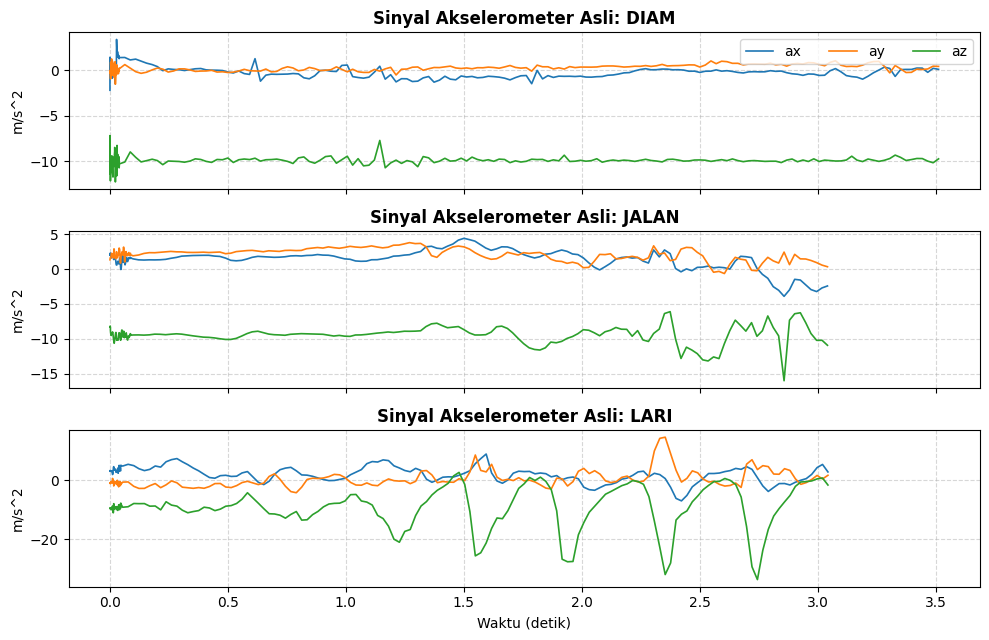

In [2]:
fig, axes = plt.subplots(3, 1, figsize=(10, 6.5), sharex=True)
for ax_plot, act in zip(axes, CLASSES):
    sample = data[data["label"] == act].iloc[:220]
    t = (sample["timestamp_ms"] - sample["timestamp_ms"].iloc[0]) / 1000.0
    ax_plot.plot(t, sample["ax"], label="ax", lw=1.2)
    ax_plot.plot(t, sample["ay"], label="ay", lw=1.2)
    ax_plot.plot(t, sample["az"], label="az", lw=1.2)
    ax_plot.set_title(f"Sinyal Akselerometer Asli: {act.upper()}", fontweight="bold")
    ax_plot.set_ylabel("m/s^2")
    ax_plot.grid(True, linestyle="--", alpha=0.5)
axes[0].legend(loc="upper right", ncol=3)
axes[-1].set_xlabel("Waktu (detik)")
plt.tight_layout()
plt.show()

## Validasi Silang Antar-Sesi (Bebas Kebocoran) & Perbandingan Model

Setiap fold menahan 1 sesi penuh per aktivitas (3 sesi uji tak terlihat: `diam`, `jalan`, `lari`).
Jendela geser ($W = 64$, $S = 32$) dibentuk secara terpisah pada data latih dan data uji.

In [3]:
folds = list(evaluation_folds(data))
models = {
    "MLP (20-16-8-3)": make_mlp,
    "Decision tree": lambda: DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random forest": lambda: RandomForestClassifier(n_estimators=30, max_depth=5, random_state=42),
}
results = {name: evaluate_folds(folds, build) for name, build in models.items()}
display(pd.DataFrame([
    {
        "Model": name,
        "Akurasi": accuracy_score(truth, predicted),
        "Macro F1": f1_score(truth, predicted, labels=CLASS_IDS, average="macro", zero_division=0),
    }
    for name, (_, truth, predicted) in results.items()
]).set_index("Model"))

,Akurasi,Macro F1
Model,,
MLP (20-16-8-3),0.979100,0.979112
Decision tree,0.979100,0.979160
Random forest,0.979904,0.979934


## Evaluasi Detail Model MLP Terpilih

Laporan klasifikasi, akurasi tiap fold sesi, dan matriks konfusi gabungan.

,Jendela latih,Jendela uji,Akurasi
Fold,,,
Sesi-1,996,248,0.919355
Sesi-2,995,249,0.991968
Sesi-3,995,249,0.995984
Sesi-4,995,249,0.995984
Sesi-5,995,249,0.991968


              precision    recall  f1-score   support

        diam       0.98      0.98      0.98       414
       jalan       0.99      0.97      0.98       415
        lari       0.97      0.98      0.97       415

    accuracy                           0.98      1244
   macro avg       0.98      0.98      0.98      1244
weighted avg       0.98      0.98      0.98      1244



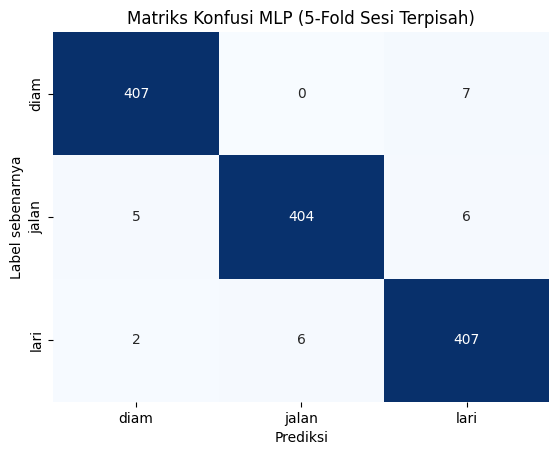

In [4]:
scores, truth, predicted = results["MLP (20-16-8-3)"]
fold_scores = pd.DataFrame(
    scores, columns=["Fold", "Jendela latih", "Jendela uji", "Akurasi"]
).set_index("Fold")
display(fold_scores)
print(classification_report(truth, predicted, labels=CLASS_IDS,
                            target_names=CLASSES, zero_division=0))
ax = sns.heatmap(confusion_matrix(truth, predicted, labels=CLASS_IDS),
                 annot=True, fmt="d", cmap="Blues", cbar=False,
                 xticklabels=CLASSES, yticklabels=CLASSES)
ax.set(xlabel="Prediksi", ylabel="Label sebenarnya", title="Matriks Konfusi MLP (5-Fold Sesi Terpisah)")
plt.show()

## Pelatihan Model Final, Verifikasi Forward Pass C++, & Ekspor ke ESP32

Setelah validasi silang, model MLP dilatih ulang pada seluruh 15 sesi rekaman asli dan
diekspor ke `ESP32_Edge_Inference_MPU6050/model_weights.h` dengan konstanta
`MODEL_ACCEL_G_TO_UNIT = 9.80665f` sesuai satuan $m/s^2$ pada `dataset_aktivitas.csv`.

In [5]:
import hashlib
from train_and_export import export_model

features, labels = extract_windows(data)
final_model = make_mlp().fit(features, labels)

# Verifikasi forward pass gaya C++ vs Scikit-Learn
sc = final_model["standardscaler"]
mlp = final_model["mlpclassifier"]
W1, W2, W3 = mlp.coefs_
b1, b2, b3 = mlp.intercepts_

def c_forward_pass(x_raw):
    z = (x_raw - sc.mean_) / sc.scale_
    h1 = np.maximum(0.0, np.dot(z, W1) + b1)
    h2 = np.maximum(0.0, np.dot(h1, W2) + b2)
    logits = np.dot(h2, W3) + b3
    exp_l = np.exp(logits - np.max(logits))
    return int(np.argmax(exp_l / np.sum(exp_l)))

c_preds = np.array([c_forward_pass(row) for row in features])
sk_preds = final_model.predict(features)
print(f"Total jendela final : {len(features)}")
print(f"Kesesuaian C++ vs SK: {np.mean(c_preds == sk_preds) * 100:.2f}%")

header_path = Path("ESP32_Edge_Inference_MPU6050/model_weights.h")
export_model(final_model, header_path, hashlib.sha256(DATASET.read_bytes()).hexdigest(), accel_unit)
print(f"Bobot berhasil diekspor ke: {header_path} ({header_path.stat().st_size:,} byte)")

Total jendela final : 1244
Kesesuaian C++ vs SK: 100.00%
Bobot berhasil diekspor ke: ESP32_Edge_Inference_MPU6050\model_weights.h (8,986 byte)
